# **Bài 1**

Mức nhiễu (std=0.2): Intercept=4.00, Slope=3.01 | MSE=0.0434 | R2=0.9855
Mức nhiễu (std=1.0): Intercept=3.78, Slope=3.13 | MSE=1.1056 | R2=0.7203
Mức nhiễu (std=2.5): Intercept=4.25, Slope=2.72 | MSE=6.5114 | R2=0.4725
Mức nhiễu (std=5.0): Intercept=3.53, Slope=4.14 | MSE=20.7805 | R2=-0.1084


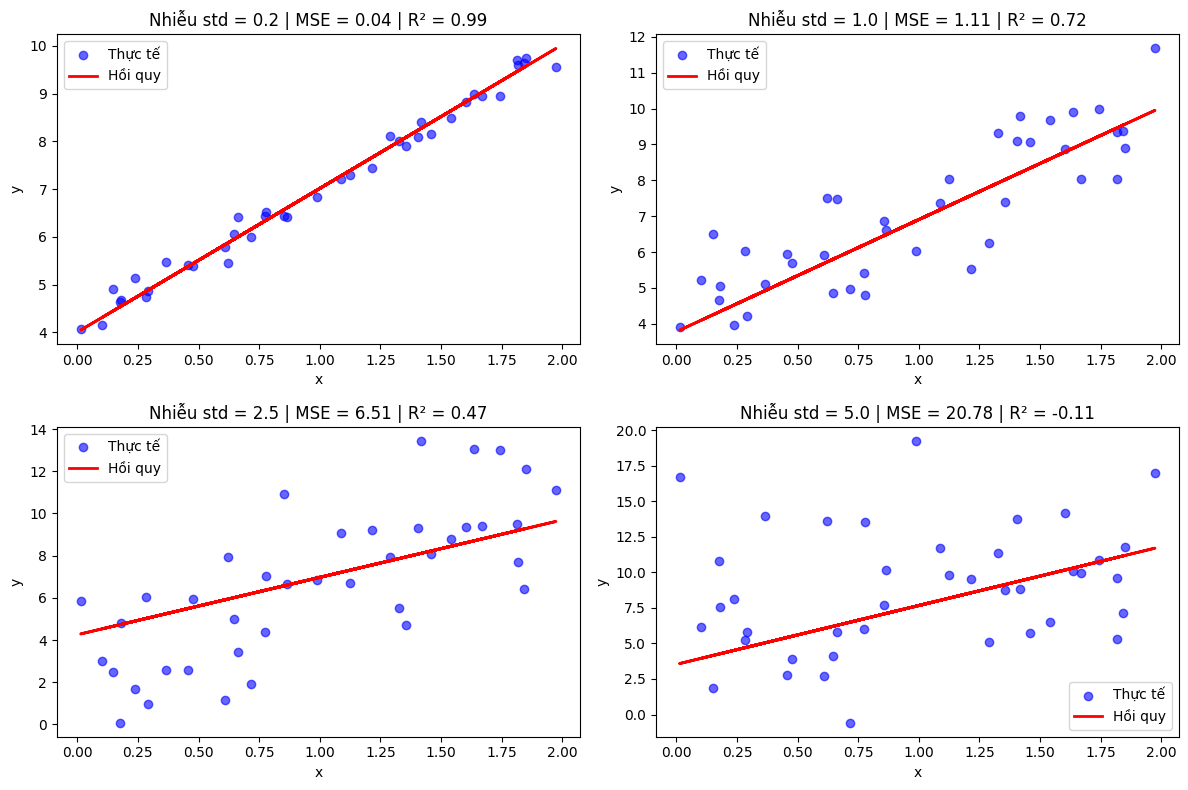

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Cố định seed để tái lập kết quả
np.random.seed(42)
X = 2 * np.random.rand(200, 1)

# Thử nghiệm với 4 mức độ nhiễu tăng dần (độ lệch chuẩn của phân phối chuẩn)
noise_levels = [0.2, 1.0, 2.5, 5.0]

plt.figure(figsize=(12, 8))

for idx, noise in enumerate(noise_levels, 1):
    # Sinh dữ liệu y với mức nhiễu tương ứng
    y = 4 + 3 * X + np.random.normal(0, noise, size=(200, 1))

    # Chia tập train/test (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Huấn luyện và dự đoán
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Tính độ đo
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Mức nhiễu (std={noise}): Intercept={model.intercept_[0]:.2f}, Slope={model.coef_[0][0]:.2f} | MSE={mse:.4f} | R2={r2:.4f}")

    # Vẽ biểu đồ so sánh
    plt.subplot(2, 2, idx)
    plt.scatter(X_test, y_test, color="blue", alpha=0.6, label="Thực tế")
    plt.plot(X_test, y_pred, color="red", linewidth=2, label="Hồi quy")
    plt.title(f"Nhiễu std = {noise} | MSE = {mse:.2f} | R² = {r2:.2f}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

plt.tight_layout()
plt.show()

# **Bài 2**

In [2]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Sử dụng bộ dữ liệu phân loại nhị phân (Ung thư vú) trong sklearn
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

# Lấy xác suất dự đoán thuộc lớp 1
y_probs = model.predict_proba(X_test)[:, 1]

# So sánh kết quả tại các ngưỡng khác nhau: 0.5, 0.6, 0.7, 0.8
thresholds = [0.5, 0.6, 0.7, 0.8]

for thresh in thresholds:
    # Áp dụng ngưỡng mới để phân loại nhãn 0 hoặc 1
    y_pred_custom = (y_probs >= thresh).astype(int)

    acc = accuracy_score(y_test, y_pred_custom)
    prec = precision_score(y_test, y_pred_custom)
    rec = recall_score(y_test, y_pred_custom)
    cm = confusion_matrix(y_test, y_pred_custom)

    print(f"=== NGƯỠNG (THRESHOLD) = {thresh} ===")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")
    print("Confusion Matrix:")
    print(cm, "\n")

=== NGƯỠNG (THRESHOLD) = 0.5 ===
Accuracy: 0.9561 | Precision: 0.9459 | Recall: 0.9859
Confusion Matrix:
[[39  4]
 [ 1 70]] 

=== NGƯỠNG (THRESHOLD) = 0.6 ===
Accuracy: 0.9737 | Precision: 0.9722 | Recall: 0.9859
Confusion Matrix:
[[41  2]
 [ 1 70]] 

=== NGƯỠNG (THRESHOLD) = 0.7 ===
Accuracy: 0.9737 | Precision: 0.9722 | Recall: 0.9859
Confusion Matrix:
[[41  2]
 [ 1 70]] 

=== NGƯỠNG (THRESHOLD) = 0.8 ===
Accuracy: 0.9737 | Precision: 0.9857 | Recall: 0.9718
Confusion Matrix:
[[42  1]
 [ 2 69]] 

